In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

In [2]:
DATA_PATH = "../data/raw/smart_home_energy_consumption_large.csv"

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (100000, 8)


,Home ID,Appliance Type,Energy Consumption (kWh),Time,Date,Outdoor Temperature (°C),Season,Household Size
0,94,Fridge,0.20,21:12,2023-12-02,-1.0,Fall,2
1,435,Oven,0.23,20:11,2023-08-06,31.1,Summer,5
2,466,Dishwasher,0.32,06:39,2023-11-21,21.3,Fall,3
3,496,Heater,3.92,21:56,2023-01-21,-4.2,Winter,1
4,137,Microwave,0.44,04:31,2023-08-26,34.5,Summer,5


In [3]:
data_dictionary = pd.DataFrame({
    "Column": [
        "Home ID", "Appliance Type", "Energy Consumption (kWh)",
        "Time", "Date", "Outdoor Temperature (°C)",
        "Season", "Household Size",
    ],
    "Data Type": [
        "int64", "string (categorical)", "float64",
        "string (HH:MM)", "string (YYYY-MM-DD)", "float64",
        "string (categorical)", "int64",
    ],
    "Unit": ["-", "-", "kWh", "24-hour clock", "date", "°C", "-", "persons"],
    "Role": [
        "Identifier (not used as a feature)", "Input feature", "TARGET",
        "Input feature (hour extracted)", "Input feature (month, weekday extracted)",
        "Input feature", "Input feature", "Input feature",
    ],
})
data_dictionary

,Column,Data Type,Unit,Role
0,Home ID,int64,-,Identifier (not used as a feature)
1,Appliance Type,string (categorical),-,Input feature
2,Energy Consumption (kWh),float64,kWh,TARGET
3,Time,string (HH:MM),24-hour clock,Input feature (hour extracted)
4,Date,string (YYYY-MM-DD),date,"Input feature (month, weekday extracted)"
5,Outdoor Temperature (°C),float64,°C,Input feature
6,Season,string (categorical),-,Input feature
7,Household Size,int64,persons,Input feature


In [4]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 8 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Home ID                   100000 non-null  int64  
 1   Appliance Type            100000 non-null  str    
 2   Energy Consumption (kWh)  100000 non-null  float64
 3   Time                      100000 non-null  str    
 4   Date                      100000 non-null  str    
 5   Outdoor Temperature (°C)  100000 non-null  float64
 6   Season                    100000 non-null  str    
 7   Household Size            100000 non-null  int64  
dtypes: float64(2), int64(2), str(4)
memory usage: 6.1 MB


,Home ID,Energy Consumption (kWh),Outdoor Temperature (°C),Household Size
count,100000.000000,100000.000000,100000.000000,100000.000000
mean,250.374980,1.499952,14.950135,3.001770
std,144.435367,1.181176,14.438755,1.417077
min,1.000000,0.100000,-10.000000,1.000000
25%,125.000000,0.590000,2.400000,2.000000
50%,250.000000,1.230000,14.900000,3.000000
75%,375.000000,1.870000,27.400000,4.000000
max,500.000000,5.000000,40.000000,5.000000


In [5]:
# Rename columns to simple, code-friendly names
df = df.rename(columns={
    "Home ID": "home_id",
    "Appliance Type": "appliance_type",
    "Energy Consumption (kWh)": "energy_kwh",
    "Time": "time",
    "Date": "date",
    "Outdoor Temperature (°C)": "outdoor_temp_c",
    "Season": "season",
    "Household Size": "household_size",
})

# Duplicates and missing values
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Missing values:", df.isnull().sum().sum())

# Date and time features
df["date"] = pd.to_datetime(df["date"])
df["hour"] = pd.to_datetime(df["time"], format="%H:%M").dt.hour
df["month"] = df["date"].dt.month
df["day_of_week"] = df["date"].dt.dayofweek      # 0 = Monday
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

df.head()

Duplicate rows: 0
Missing values: 0


,home_id,appliance_type,energy_kwh,time,date,outdoor_temp_c,season,household_size,hour,month,day_of_week,is_weekend
0,94,Fridge,0.20,21:12,2023-12-02,-1.0,Fall,2,21,12,5,1
1,435,Oven,0.23,20:11,2023-08-06,31.1,Summer,5,20,8,6,1
2,466,Dishwasher,0.32,06:39,2023-11-21,21.3,Fall,3,6,11,1,0
3,496,Heater,3.92,21:56,2023-01-21,-4.2,Winter,1,21,1,5,1
4,137,Microwave,0.44,04:31,2023-08-26,34.5,Summer,5,4,8,5,1


In [6]:
# 1) Does the Season label match the month?
print(pd.crosstab(df["month"], df["season"]))

# 2) Consumption by appliance (high values for heater/AC are expected, not errors)
print(df.groupby("appliance_type")["energy_kwh"].describe().round(2))

season  Fall  Spring  Summer  Winter
month                               
1          0       0       0    8787
2          0       0       0    7670
3          0       0       0    8439
4          0    8312       0       0
5          0    8439       0       0
6          0    8361       0       0
7          0       0    8450       0
8          0       0    8362       0
9          0       0    8154       0
10      8621       0       0       0
11      8146       0       0       0
12      8259       0       0       0
                    count  mean   std  min   25%   50%   75%  max
appliance_type                                                   
Air Conditioning  10067.0  3.50  0.87  2.0  2.76  3.49  4.26  5.0
Computer           9944.0  1.10  0.52  0.2  0.64  1.09  1.55  2.0
Dishwasher        10095.0  1.10  0.52  0.2  0.65  1.10  1.55  2.0
Fridge             9931.0  0.30  0.12  0.1  0.20  0.30  0.40  0.5
Heater            10018.0  3.49  0.87  2.0  2.74  3.48  4.22  5.0
Lights            10

In [7]:
df.to_csv("../data/processed/cleaned_energy_data.csv", index=False)
print("Saved:", df.shape)

Saved: (100000, 12)


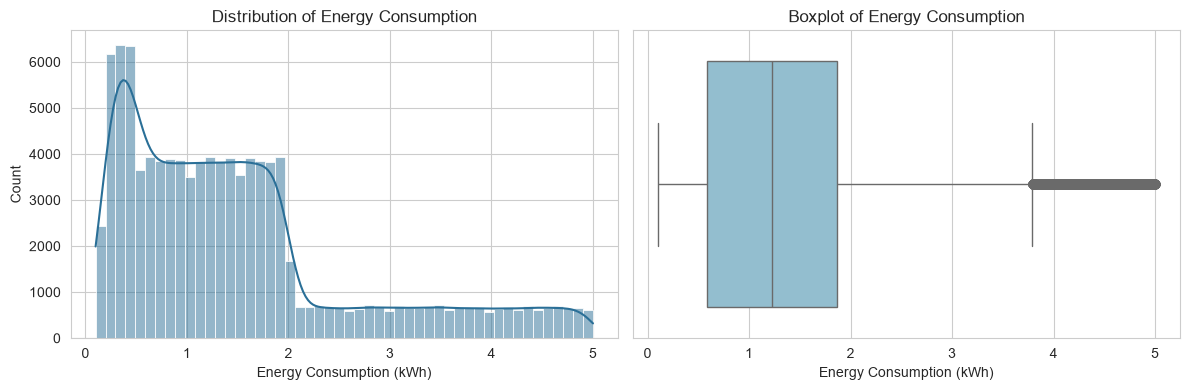

count    100000.000
mean          1.500
std           1.181
min           0.100
25%           0.590
50%           1.230
75%           1.870
max           5.000
Name: energy_kwh, dtype: float64

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["energy_kwh"], bins=50, kde=True, ax=axes[0], color="#2a6f97")
axes[0].set_title("Distribution of Energy Consumption")
axes[0].set_xlabel("Energy Consumption (kWh)")

sns.boxplot(x=df["energy_kwh"], ax=axes[1], color="#89c2d9")
axes[1].set_title("Boxplot of Energy Consumption")
axes[1].set_xlabel("Energy Consumption (kWh)")

plt.tight_layout()
plt.savefig("../outputs/figures/01_target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

df["energy_kwh"].describe().round(3)

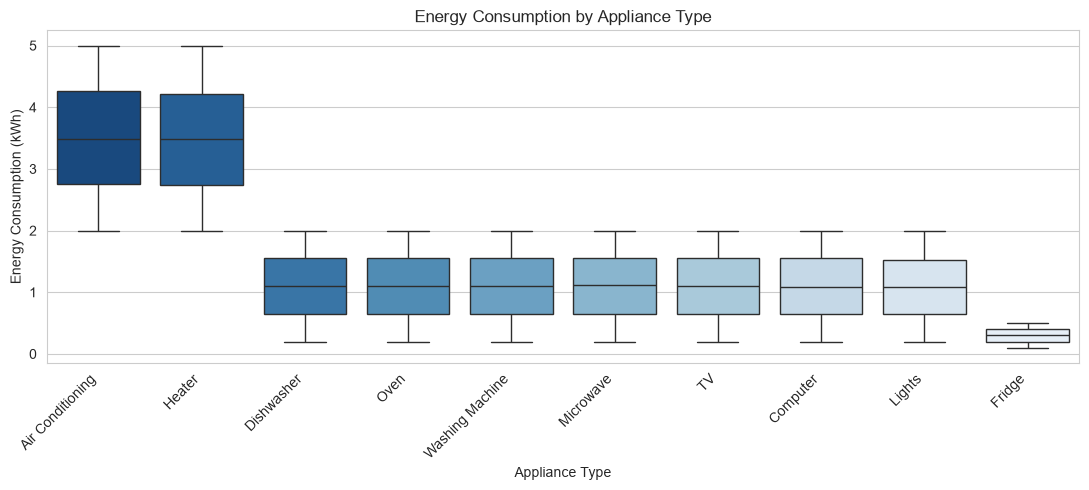

In [9]:
order = df.groupby("appliance_type")["energy_kwh"].mean().sort_values(ascending=False).index

plt.figure(figsize=(11, 5))
sns.boxplot(data=df, x="appliance_type", y="energy_kwh", order=order, palette="Blues_r")
plt.xticks(rotation=45, ha="right")
plt.title("Energy Consumption by Appliance Type")
plt.xlabel("Appliance Type")
plt.ylabel("Energy Consumption (kWh)")
plt.tight_layout()
plt.savefig("../outputs/figures/02_energy_by_appliance.png", dpi=150, bbox_inches="tight")
plt.show()

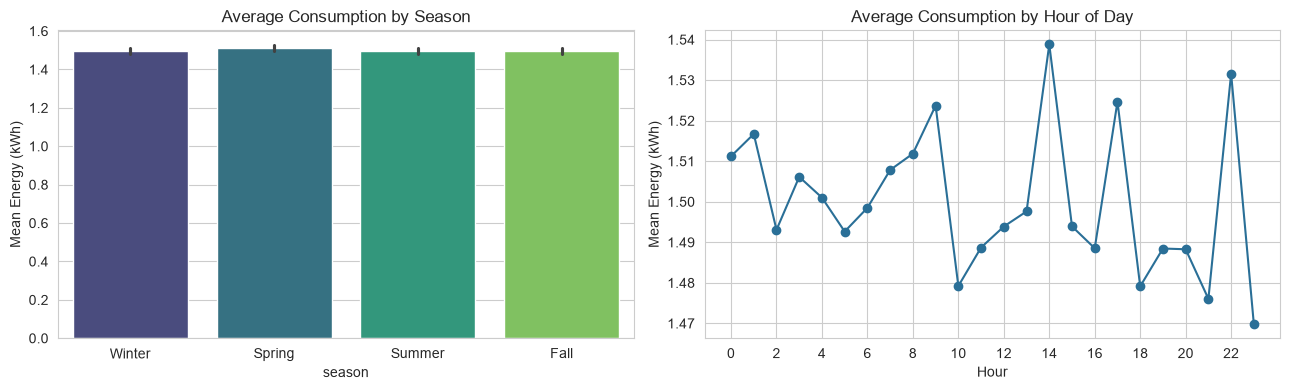

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

season_order = ["Winter", "Spring", "Summer", "Fall"]
sns.barplot(data=df, x="season", y="energy_kwh", order=season_order, ax=axes[0], palette="viridis")
axes[0].set_title("Average Consumption by Season")
axes[0].set_ylabel("Mean Energy (kWh)")

hourly = df.groupby("hour")["energy_kwh"].mean()
axes[1].plot(hourly.index, hourly.values, marker="o", color="#2a6f97")
axes[1].set_title("Average Consumption by Hour of Day")
axes[1].set_xlabel("Hour")
axes[1].set_ylabel("Mean Energy (kWh)")
axes[1].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.savefig("../outputs/figures/03_season_and_hour.png", dpi=150, bbox_inches="tight")
plt.show()

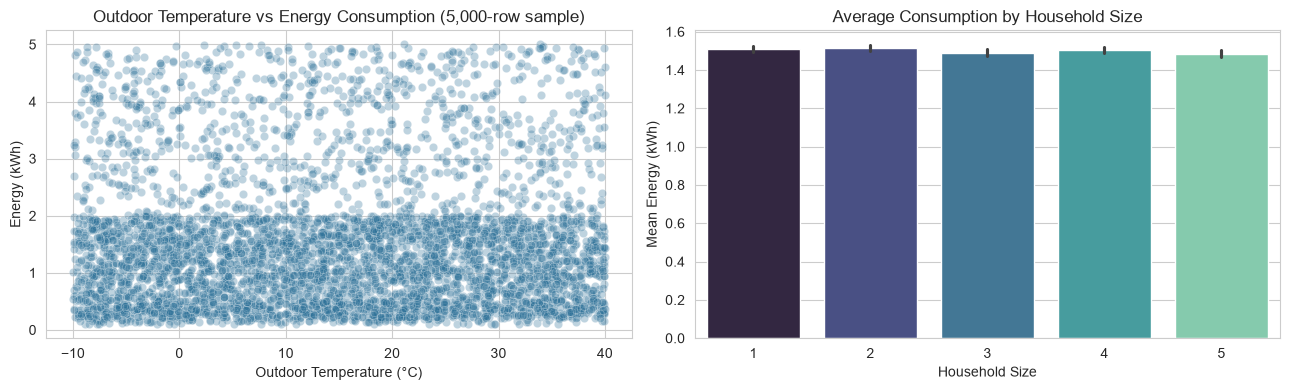

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sample = df.sample(5000, random_state=42)
sns.scatterplot(data=sample, x="outdoor_temp_c", y="energy_kwh", alpha=0.3, ax=axes[0], color="#2a6f97")
axes[0].set_title("Outdoor Temperature vs Energy Consumption (5,000-row sample)")
axes[0].set_xlabel("Outdoor Temperature (°C)")
axes[0].set_ylabel("Energy (kWh)")

sns.barplot(data=df, x="household_size", y="energy_kwh", ax=axes[1], palette="mako")
axes[1].set_title("Average Consumption by Household Size")
axes[1].set_xlabel("Household Size")
axes[1].set_ylabel("Mean Energy (kWh)")

plt.tight_layout()
plt.savefig("../outputs/figures/04_temp_and_household.png", dpi=150, bbox_inches="tight")
plt.show()

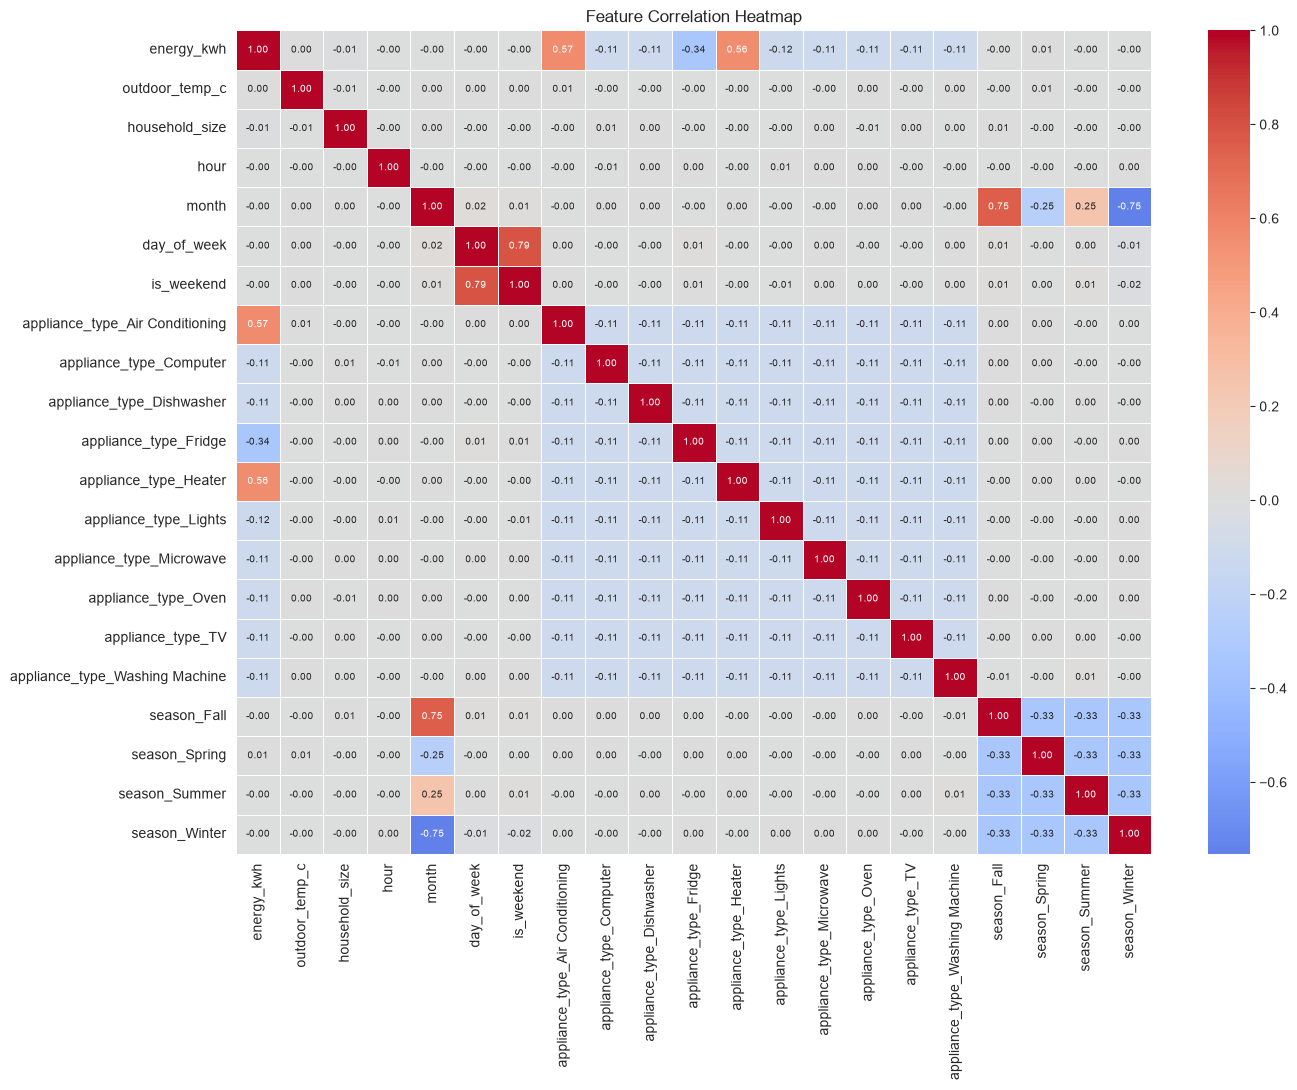

In [12]:
corr_df = df[["energy_kwh", "outdoor_temp_c", "household_size", "hour",
              "month", "day_of_week", "is_weekend", "appliance_type", "season"]]
corr_df = pd.get_dummies(corr_df, columns=["appliance_type", "season"], dtype=int)

corr = corr_df.corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            annot_kws={"size": 7}, linewidths=0.4)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig("../outputs/figures/05_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
corr["energy_kwh"].drop("energy_kwh").sort_values(key=abs, ascending=False).round(3)

appliance_type_Air Conditioning    0.566
appliance_type_Heater              0.561
appliance_type_Fridge             -0.338
appliance_type_Lights             -0.118
appliance_type_Computer           -0.114
appliance_type_TV                 -0.113
appliance_type_Dishwasher         -0.113
appliance_type_Microwave          -0.112
appliance_type_Washing Machine    -0.112
appliance_type_Oven               -0.112
household_size                    -0.007
season_Spring                      0.005
hour                              -0.004
day_of_week                       -0.004
season_Summer                     -0.002
outdoor_temp_c                     0.002
month                             -0.002
season_Winter                     -0.002
season_Fall                       -0.001
is_weekend                        -0.001
Name: energy_kwh, dtype: float64